# ES 335: Data exploration, uncertainty and error analysis
1. What the data looks like (summaries and plots, data-quality checks).
2. How much of yield is fixed by *which county it is* (why the county-mean baseline is strong).
3. Final 2022 test of the anomaly model (Setting A). It was chosen on 2021 in notebook 02 and is evaluated **once** here.
4. Uncertainty: are the model-vs-baseline differences larger than chance? (bootstrap that resamples whole states)
5. Representative errors: which counties the model gets most wrong, and how error depends on yield level.

Figures go to `figures/`, tables to `es335_crop/`.

In [1]:
import os, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
warnings.filterwarnings("ignore")

try:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_DIR, FIG_DIR = "/content/drive/MyDrive/es335_crop", "/content/drive/MyDrive/es335_figures"
except ImportError:
    DATA_DIR = os.environ.get("ES335_DATA_DIR", "es335_crop" if os.path.isdir("es335_crop") else "../es335_crop")
    FIG_DIR = "figures" if os.path.isdir("es335_crop") else "../figures"
os.makedirs(FIG_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

df = pd.read_csv(f"{DATA_DIR}/corn_model_table.csv", dtype={"FIPS": str, "STATEFP": str})
cy = pd.read_csv(f"{DATA_DIR}/corn_yield.csv", dtype={"FIPS": str}); cy["FIPS"] = cy["FIPS"].str.zfill(5)
weather_cols = [c for c in df.columns if re.match(r"(tavg|tmax|tmin|precip|rh|vpd|srad|heat_days)_", c)]
soil_cols = [c for c in df.columns if c.startswith(("nitrogen", "soc", "phh2o"))]
geo_cols = ["lat", "lon"]
full_cols = weather_cols + geo_cols + soil_cols
ABBR = {"01":"AL","04":"AZ","05":"AR","06":"CA","08":"CO","09":"CT","10":"DE","12":"FL","13":"GA","16":"ID","17":"IL","18":"IN","19":"IA","20":"KS","21":"KY","22":"LA","23":"ME","24":"MD","25":"MA","26":"MI","27":"MN","28":"MS","29":"MO","30":"MT","31":"NE","32":"NV","33":"NH","34":"NJ","35":"NM","36":"NY","37":"NC","38":"ND","39":"OH","40":"OK","41":"OR","42":"PA","44":"RI","45":"SC","46":"SD","47":"TN","48":"TX","49":"UT","50":"VT","51":"VA","53":"WA","54":"WV","55":"WI","56":"WY"}
df["state"] = df["STATEFP"].map(ABBR)

def scores(y, p):
    return {"RMSE": np.sqrt(mean_squared_error(y, p)), "MAE": mean_absolute_error(y, p), "R2": r2_score(y, p)}
print(df.shape)

(8691, 63)


## 1. Data overview and quality checks

In [2]:
overview = pd.DataFrame({
    "rows (county-years)": df.groupby("Year").size(),
    "counties": df.groupby("Year")["FIPS"].nunique(),
    "states": df.groupby("Year")["STATEFP"].nunique(),
    "mean yield": df.groupby("Year")["Yield"].mean().round(1),
    "median yield": df.groupby("Year")["Yield"].median().round(1),
})
overview.loc["all"] = [len(df), df["FIPS"].nunique(), df["STATEFP"].nunique(), round(df["Yield"].mean(), 1), round(df["Yield"].median(), 1)]
print(overview.to_string())

n_years = df.groupby("FIPS")["Year"].nunique()
corn_rows = cy[cy["Year"].between(2017, 2022)]
quality = pd.Series({
    "USDA corn county-years 2017-2022 (before joins)": len(corn_rows),
    "rows in final table (after weather/soil/geo joins)": len(df),
    "rows lost at the weather join": len(corn_rows) - len(df),
    "missing values in final table": int(df.isna().sum().sum()),
    "counties": df["FIPS"].nunique(),
    "counties observed in only 1 year": int((n_years == 1).sum()),
    "counties observed in all 6 years": int((n_years == 6).sum()),
    "county-years with < 100 mm Apr-Sep rain (real, dry west)": int((df["precip_season"] < 100).sum()),
    "weather files that failed to download": len(pd.read_csv(f"{DATA_DIR}/hrrr_skipped.csv")),
    "yield min / max (bu/acre)": f"{df['Yield'].min():.1f} / {df['Yield'].max():.1f}",
})
print(quality.to_string())
quality.rename("value").to_csv(f"{DATA_DIR}/data_quality_summary.csv")

      rows (county-years)  counties  states  mean yield  median yield
Year                                                                 
2017                 1444      1444      31       162.3         167.2
2018                 1343      1343      32       159.3         164.7
2019                 1255      1255      31       154.3         157.5
2020                 1665      1665      31       155.2         161.6
2021                 1469      1469      32       163.4         169.3
2022                 1515      1515      32       153.4         160.5
all                  8691      1898      32       158.0         163.6
USDA corn county-years 2017-2022 (before joins)                     8739
rows in final table (after weather/soil/geo joins)                  8691
rows lost at the weather join                                         48
missing values in final table                                          0
counties                                                            1898
count

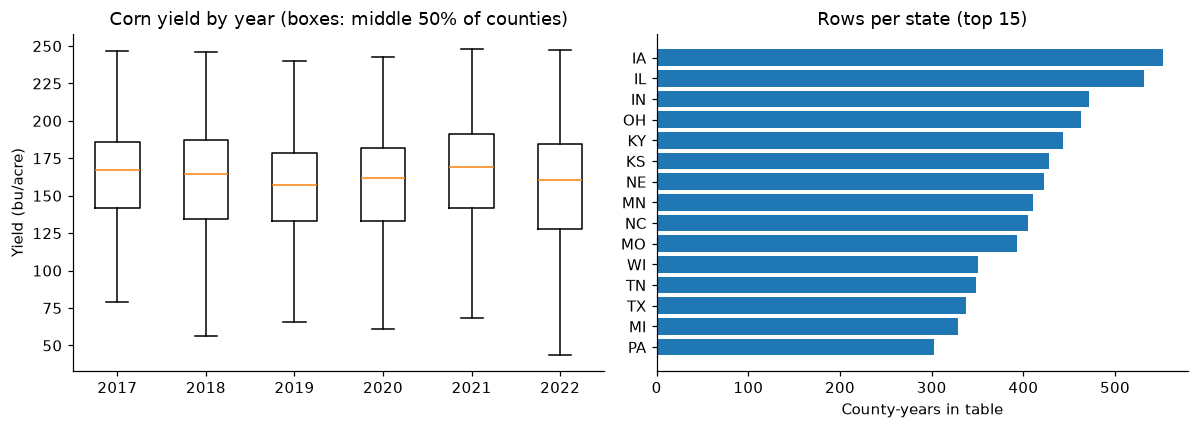

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
years = sorted(df["Year"].unique())
axes[0].boxplot([df.loc[df["Year"] == y, "Yield"] for y in years], showfliers=False)
axes[0].set_xticks(range(1, len(years) + 1), years)
axes[0].set_ylabel("Yield (bu/acre)"); axes[0].set_title("Corn yield by year (boxes: middle 50% of counties)")
top = df["state"].value_counts().head(15)
axes[1].barh(top.index[::-1], top.values[::-1])
axes[1].set_xlabel("County-years in table"); axes[1].set_title("Rows per state (top 15)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/07_yield_by_year_and_rows_by_state.png", bbox_inches="tight"); plt.show()

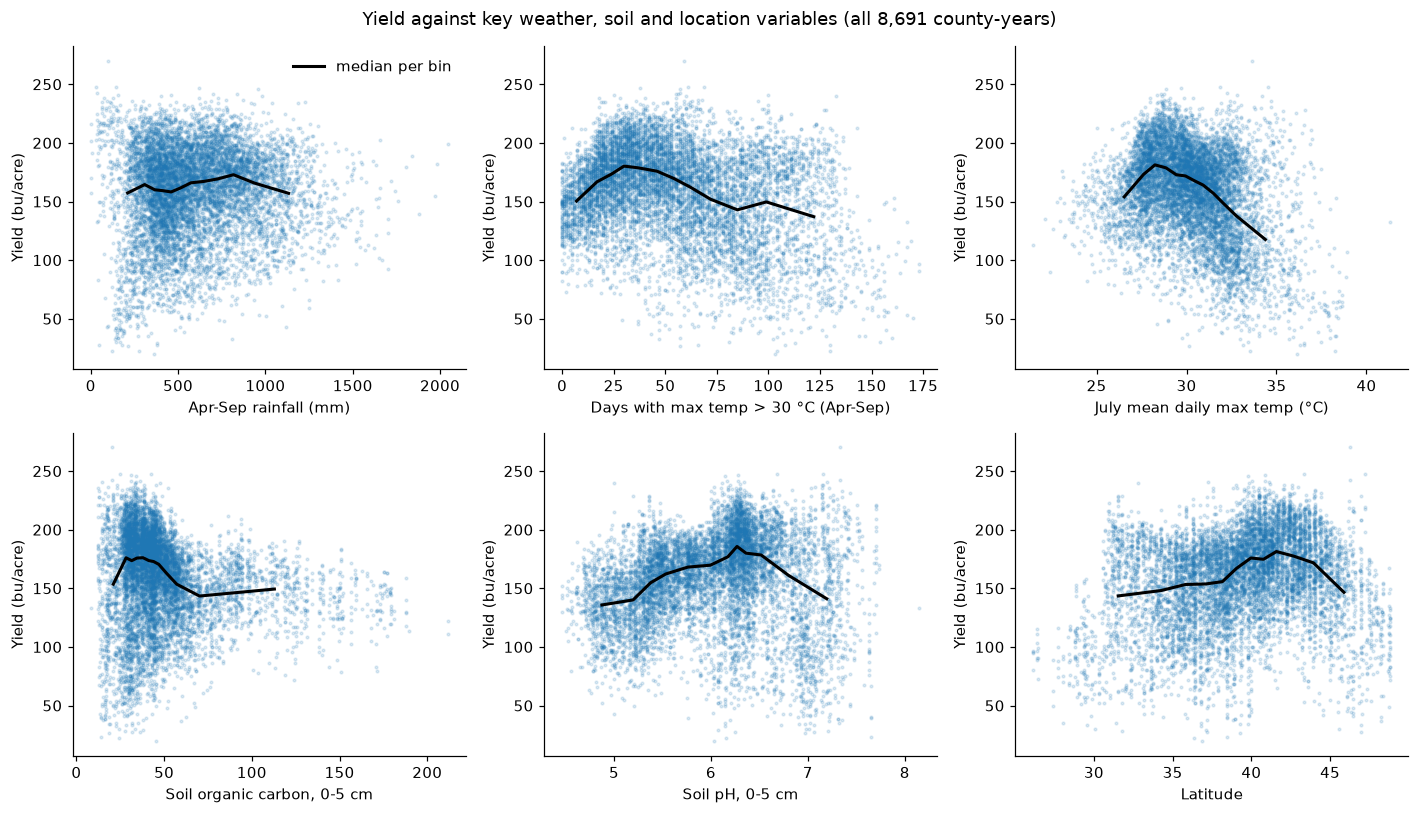

Spearman correlation with yield:
precip_season       0.04
heat_days_season   -0.19
tmax_m07           -0.27
soc_0-5cm          -0.19
phh2o_0-5cm         0.21
lat                 0.21


In [4]:
def binned(ax, x, y, bins=12):
    q = pd.qcut(x, bins, duplicates="drop")
    g = pd.DataFrame({"x": x, "y": y}).groupby(q, observed=True).median()
    ax.plot(g["x"], g["y"], color="black", lw=2, label="median per bin")

fig, axes = plt.subplots(2, 3, figsize=(13, 7.5))
pairs = [("precip_season", "Apr-Sep rainfall (mm)"), ("heat_days_season", "Days with max temp > 30 °C (Apr-Sep)"),
         ("tmax_m07", "July mean daily max temp (°C)"), ("soc_0-5cm", "Soil organic carbon, 0-5 cm"),
         ("phh2o_0-5cm", "Soil pH, 0-5 cm"), ("lat", "Latitude")]
for ax, (c, label) in zip(axes.ravel(), pairs):
    ax.scatter(df[c], df["Yield"], s=3, alpha=0.15)
    binned(ax, df[c], df["Yield"])
    ax.set_xlabel(label); ax.set_ylabel("Yield (bu/acre)")
axes[0, 0].legend(frameon=False)
fig.suptitle("Yield against key weather, soil and location variables (all 8,691 county-years)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/08_yield_vs_key_variables.png", bbox_inches="tight"); plt.show()

print("Spearman correlation with yield:")
print(df[[c for c, _ in pairs] + ["Yield"]].corr(method="spearman")["Yield"].drop("Yield").round(2).to_string())

## 2. How much of yield is explained by the county itself?
If most variation is *between* counties (some counties always yield more), a county's own average is a very strong predictor, and weather can only explain the smaller *within-county*, year-to-year part. This is why the county-mean baseline is hard to beat.

In [5]:
multi = df[df.groupby("FIPS")["Year"].transform("nunique") >= 2]
total_var = multi["Yield"].var(ddof=0)
within_var = (multi["Yield"] - multi.groupby("FIPS")["Yield"].transform("mean")).var(ddof=0)
print(f"counties with 2+ years: {multi['FIPS'].nunique()}, rows: {len(multi)}")
print(f"share of yield variance BETWEEN counties: {1 - within_var / total_var:.1%}")
print(f"share WITHIN counties (year-to-year):     {within_var / total_var:.1%}")
print(f"typical year-to-year SD inside a county:  {np.sqrt(within_var):.1f} bu/acre")

counties with 2+ years: 1762, rows: 8555
share of yield variance BETWEEN counties: 81.1%
share WITHIN counties (year-to-year):     18.9%
typical year-to-year SD inside a county:  16.3 bu/acre


## 3. Final 2022 test of the anomaly model (Setting A)
Same method and settings as notebook 02 (HGB, weather+geo+soil, chosen on 2021). Here it is trained on 2017-2021 and scored once on 2022.
Prediction = county mean of training years + model's predicted departure, where the model sees each year's weather *departures* from that county's normal.

In [6]:
def anomaly_model(train, val):
    cols = ["Yield"] + weather_cols
    x = train[cols]
    sums = train.groupby("FIPS")[cols].transform("sum"); cnt = train.groupby("FIPS")[cols].transform("count")
    loo = (sums - x.fillna(0)) / (cnt - x.notna().astype(int))          # leave-one-year-out county means
    keep = train.groupby("FIPS")["Yield"].transform("count") >= 2
    tr, loo = train[keep], loo[keep]
    Xtr = (tr[weather_cols] - loo[weather_cols]).join(tr[geo_cols + soil_cols])
    ytr = tr["Yield"] - loo["Yield"]

    cm = train.groupby("FIPS")[cols].mean().reindex(val["FIPS"])
    known = val["FIPS"].isin(train["FIPS"]).values
    Xva = pd.DataFrame(val[weather_cols].values - cm[weather_cols].values, columns=weather_cols, index=val.index).join(val[geo_cols + soil_cols])
    fallback = val["STATEFP"].map(train.groupby("STATEFP")["Yield"].mean()).fillna(train["Yield"].mean())
    base = pd.Series(cm["Yield"].values, index=val.index).fillna(fallback)

    m = HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, max_depth=4, min_samples_leaf=40, random_state=42).fit(Xtr, ytr)
    corr = pd.Series(m.predict(Xva), index=val.index); corr[~known] = 0.0
    return base + corr, base

def direct_model(train, val, params):
    m = HistGradientBoostingRegressor(**params, random_state=42).fit(train[full_cols], train["Yield"])
    return pd.Series(m.predict(val[full_cols]), index=val.index)

preds = {}
for year, params in [(2021, dict(max_iter=300, learning_rate=0.05)),
                     (2022, dict(learning_rate=0.1, max_iter=500, min_samples_leaf=20))]:
    tr, te = df[df["Year"] < year], df[df["Year"] == year].copy()
    te["anomaly"], te["baseline"] = anomaly_model(tr, te)
    te["direct"] = direct_model(tr, te, params)
    preds[year] = te

res = []
for year, te in preds.items():
    for name in ["baseline", "direct", "anomaly"]:
        res.append({"year": year, "role": "validation" if year == 2021 else "final test", "model": name,
                    **{k: round(v, 2) for k, v in scores(te["Yield"], te[name]).items()}})
res = pd.DataFrame(res)
print(res.to_string(index=False))
res.to_csv(f"{DATA_DIR}/final_comparison_2021_2022.csv", index=False)

 year       role    model  RMSE   MAE   R2
 2021 validation baseline 23.83 18.77 0.61
 2021 validation   direct 25.61 20.07 0.55
 2021 validation  anomaly 20.38 15.42 0.71
 2022 final test baseline 25.48 18.97 0.65
 2022 final test   direct 24.90 18.82 0.67
 2022 final test  anomaly 21.82 15.88 0.74


## 4. Uncertainty: state-level bootstrap
Counties in the same state share weather, so their errors are correlated; resampling individual counties would make intervals too narrow. We resample **whole states** with replacement 2,000 times and recompute the RMSE difference (baseline minus model; positive = model better).
This only measures uncertainty from *which counties/states* are in the evaluation year. It cannot tell us how the model would do in other years (we have one test year).

In [7]:
rng = np.random.default_rng(42)
def boot_diff(te, model, n=2000):
    st = te["STATEFP"].values; states = np.unique(st)
    idx = {s: np.where(st == s)[0] for s in states}
    eb, em = (te["Yield"] - te["baseline"]).values, (te["Yield"] - te[model]).values
    rm = lambda e: np.sqrt(np.mean(e ** 2))
    d = []
    for _ in range(n):
        pick = np.concatenate([idx[s] for s in rng.choice(states, len(states))])
        d.append(rm(eb[pick]) - rm(em[pick]))
    return rm(eb) - rm(em), *np.percentile(d, [2.5, 97.5])

rows = []
for year, te in preds.items():
    for model in ["direct", "anomaly"]:
        diff, lo, hi = boot_diff(te, model)
        rows.append({"year": year, "model": model, "RMSE_baseline_minus_model": round(diff, 2),
                     "ci95_low": round(lo, 2), "ci95_high": round(hi, 2),
                     "clearly_better_than_baseline": lo > 0, "clearly_worse": hi < 0})
boot = pd.DataFrame(rows)
print(boot.to_string(index=False))
boot.to_csv(f"{DATA_DIR}/bootstrap_ci.csv", index=False)

 year   model  RMSE_baseline_minus_model  ci95_low  ci95_high  clearly_better_than_baseline  clearly_worse
 2021  direct                      -1.78     -4.39       0.70                         False          False
 2021 anomaly                       3.45      1.42       5.35                          True          False
 2022  direct                       0.58     -2.13       2.98                         False          False
 2022 anomaly                       3.66      2.46       4.95                          True          False


## 5. Representative errors (2022 test year)

In [8]:
te = preds[2022].copy()
te["history_years"] = te["FIPS"].map(df[df["Year"] <= 2021].groupby("FIPS").size()).fillna(0).astype(int)
for m in ["direct", "anomaly", "baseline"]:
    te[f"err_{m}"] = te["Yield"] - te[m]          # positive = model under-predicted
show = ["FIPS", "state", "history_years", "Yield", "baseline", "direct", "anomaly", "precip_season", "heat_days_season"]

worst = te.reindex(te["err_anomaly"].abs().sort_values(ascending=False).index).head(10)
print("10 largest anomaly-model errors in 2022:")
print(worst[show + ["err_anomaly"]].round(1).to_string(index=False))

typical = te.iloc[(te["err_anomaly"].abs() - te["err_anomaly"].abs().median()).abs().argsort()[:3]]
print("\nThree counties with a typical (median-sized) error:")
print(typical[show + ["err_anomaly"]].round(1).to_string(index=False))

out = pd.concat([worst.assign(kind="largest error"), typical.assign(kind="typical error")])
out[["kind"] + show + ["err_direct", "err_anomaly"]].round(1).to_csv(f"{DATA_DIR}/representative_errors_2022.csv", index=False)

te["yield_band"] = pd.qcut(te["Yield"], 5, labels=["lowest 20%", "20-40%", "40-60%", "60-80%", "highest 20%"])
band = te.groupby("yield_band", observed=True).agg(n=("Yield", "size"), actual=("Yield", "mean"),
        mean_err_direct=("err_direct", "mean"), mean_err_anomaly=("err_anomaly", "mean"),
        rmse_anomaly=("err_anomaly", lambda e: np.sqrt((e ** 2).mean()))).round(1)
hist = (te.assign(history=pd.cut(te["history_years"], [-1, 0, 1, 3, 5], labels=["none (state mean)", "1 year", "2-3 years", "4-5 years"]))
          .groupby("history", observed=True).agg(n=("Yield", "size"), mean_yield=("Yield", "mean"),
            rmse_baseline=("err_baseline", lambda e: np.sqrt((e ** 2).mean())),
            rmse_anomaly=("err_anomaly", lambda e: np.sqrt((e ** 2).mean()))).round(1))
print("\n2022 error by how many earlier years the county was observed:"); print(hist.to_string())
hist.to_csv(f"{DATA_DIR}/error_by_history_2022.csv")

print("\nError by actual-yield band (mean error > 0 means under-prediction):"); print(band.to_string())

10 largest anomaly-model errors in 2022:
 FIPS state  history_years  Yield  baseline  direct  anomaly  precip_season  heat_days_season  err_anomaly
13147    GA              3   72.1     175.8   164.8    177.4          295.6              83.0       -105.3
28059    MS              0   65.2     169.3   144.1    169.3          638.2             100.0       -104.1
13211    GA              0   63.1     165.0   166.0    165.0          471.4              83.0       -101.9
28041    MS              0   77.4     169.3   164.5    169.3          624.3             126.0        -91.9
13241    GA              0   77.8     165.0   139.8    165.0          497.4               7.0        -87.2
48099    TX              0   35.0     114.5   130.7    114.5          179.3             147.0        -79.5
13233    GA              1   88.9     167.1   149.2    166.8          423.1              72.0        -77.9
40037    OK              1   39.1     128.9    92.6    116.3          531.9             116.0        -7

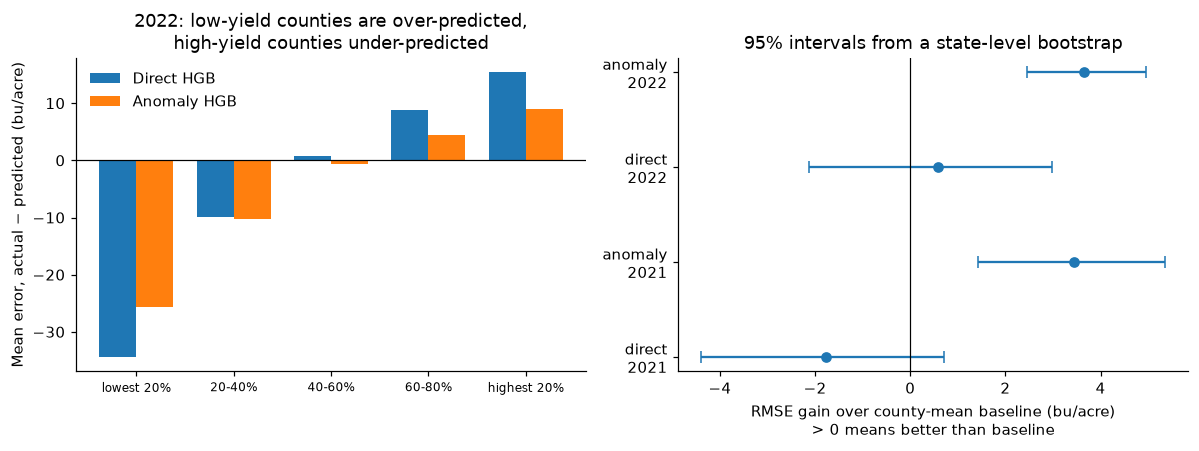

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
x = np.arange(len(band)); w = 0.38
axes[0].bar(x - w/2, band["mean_err_direct"], w, label="Direct HGB")
axes[0].bar(x + w/2, band["mean_err_anomaly"], w, label="Anomaly HGB")
axes[0].axhline(0, color="black", lw=0.8); axes[0].set_xticks(x, band.index, fontsize=8)
axes[0].set_ylabel("Mean error, actual − predicted (bu/acre)")
axes[0].set_title("2022: low-yield counties are over-predicted,\nhigh-yield counties under-predicted"); axes[0].legend(frameon=False)

b = boot.copy(); lab = [f"{r.model}\n{r.year}" for r in b.itertuples()]
axes[1].errorbar(b["RMSE_baseline_minus_model"], range(len(b)),
                 xerr=[b["RMSE_baseline_minus_model"] - b["ci95_low"], b["ci95_high"] - b["RMSE_baseline_minus_model"]],
                 fmt="o", capsize=4)
axes[1].axvline(0, color="black", lw=0.8); axes[1].set_yticks(range(len(b)), lab)
axes[1].set_xlabel("RMSE gain over county-mean baseline (bu/acre)\n> 0 means better than baseline")
axes[1].set_title("95% intervals from a state-level bootstrap")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/09_error_by_yield_band_and_bootstrap.png", bbox_inches="tight"); plt.show()